# 03 – BERT İnce Ayarı (İngilizce RoBERTa, Türkçe BERTurk)
**Sahibi:** Bilge · **Amaç:** İngilizce için `FacebookAI/roberta-base`, Türkçe için `dbmdz/bert-base-turkish-cased` modelini ince ayarlamak ve ortak test setlerinde tahmin üretmek.
**Girdi:** `data/processed/{en,tr}_{train,val,test}.csv`
**Çıktı:** `predictions/bert_{en,tr}.csv`, `results/logs/bert_{en,tr}_log.csv`, `results/figures/bert_{en,tr}_loss.png`, `results/tables/bert_parametreler.csv`, `results/hata_ornekleri/bert.csv`; en iyi modeller Drive'da `bim448/models/bert_{en,tr}/best`

**Not:** 2. bölümdeki `DEBUG = True` ayarıyla notebook birkaç dakikada baştan sona çalışır, çıktılar `_debug` ekiyle kaydedilir ve GitHub'a gönderilmez. Asıl eğitim `DEBUG = False` ile T4 GPU'da yapılmıştır (dil başına yaklaşık 11 dakika). Asıl eğitimde warmup kullanılmamıştır; bu durum raporun 5.9 bölümünde belirtilmiştir.

## 1. Kurulum

In [ ]:
# Ortak kurulum hücresi: Drive'ı bağlar, depoyu indirir/günceller, kütüphaneleri kurar
from google.colab import userdata, drive
import os

drive.mount('/content/drive')

TOKEN = userdata.get('GITHUB_TOKEN')
REPO_OWNER = "bilgeerol"
REPO = "bim448-sentiment"
REPO_DIR = f"/content/{REPO}"

if not os.path.exists(REPO_DIR):
    !git clone https://{TOKEN}@github.com/{REPO_OWNER}/{REPO}.git {REPO_DIR}
%cd {REPO_DIR}
!git pull
!git config user.name "Bilge Erol"
!git config user.email "bilgeerol02@gmail.com"
!pip install -q transformers datasets accelerate scikit-learn

## 2. Çalışma modu

In [ ]:
# Çalışma modu: True = hızlı deneme (300/150/150 örnek, dosyalar _debug ekiyle, push yok); False = asıl eğitim
DEBUG = True
EK = "_debug" if DEBUG else ""
print("Mod:", "DEBUG (hızlı deneme)" if DEBUG else "ASIL EĞİTİM")

## 3. İngilizce: RoBERTa ince ayarı ve test tahminleri (B3)

*Bu hücrenin altındaki çıktı, `DEBUG = False` ile yapılan asıl eğitime (18 Kasım) aittir.*

Veri boyutları -> Train: 30000, Val: 3000, Test: 3000
📊 Test metinlerinin %3.20'si 128 tokenı aşıyor.


Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.530692,0.502563,0.787000,0.789149,0.787000,0.785874
2,0.456697,0.489515,0.800333,0.801637,0.800333,0.800877
3,0.427448,0.507693,0.802333,0.802623,0.802333,0.802372


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

⏱️ Toplam eğitim süresi: 638.98 saniye


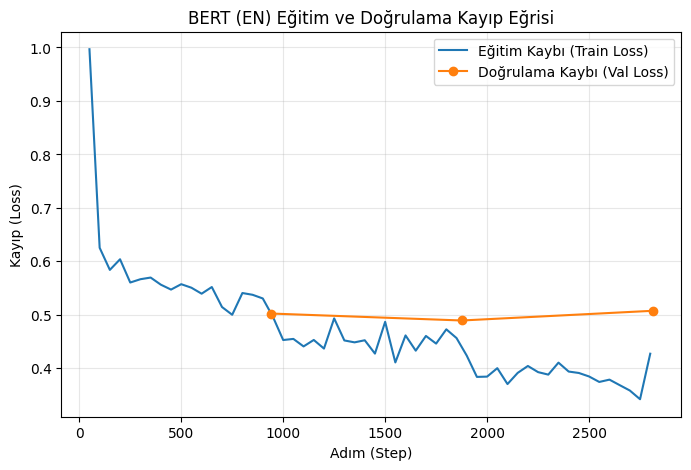

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ predictions/bert_en.csv (3.000 satır) başarıyla kaydedildi!
[main c35c766] [Bilge] BERT İngilizce (3000 satır) tahminleri, log ve kayıp grafiği eklendi
 3 files changed, 3061 insertions(+), 150 deletions(-)
 create mode 100644 results/figures/bert_en_loss.png
 create mode 100644 results/logs/bert_en_log.csv
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (1/1), done.
remote: Total 7 (delta 6), reused 7 (delta 6), pack-reused 0 (from 0)
Unpacking objects: 100% (7/7), 3.84 KiB | 327.00 KiB/s, done.
From https://github.com/BilgeErol/bim448-sentiment
   025dd6e..76b0284  main       -> origin/main
Successfully rebased and updated refs/heads/main.
Enumerating objects: 15, done.
Counting objects: 100% (15/15), done.
Delta compression using up to 2 threads
Compressing objects: 100% (9/9), done.
Writing objects: 100% (9/9), 363.09 KiB | 6.26 MiB/s, done.
Total 9 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolvin

In [ ]:
# B3: İNGİLİZCE ROBERTA TAM EĞİTİM VE 3.000 SATIRLIK TAHMİN + LOG + GRAFİK (Güncellendi)
import pandas as pd
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

LANG = "en"
MODEL_NAME = "FacebookAI/roberta-base"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 3
SEED = 42
OUTPUT_DIR = f"/content/drive/MyDrive/bim448/models/bert_{LANG}{EK}"  # DEBUG: ayrı klasör

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# 1. Tam Veriyi Oku (30.000 train, 3.000 val, 3.000 test)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv")
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv")
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv")

if DEBUG:  # hızlı deneme: 300 eğitim / 150 doğrulama / 150 test örneği
    train_df = train_df.sample(300, random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(150, random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(150, random_state=SEED).reset_index(drop=True)

print(f"Veri boyutları -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

train_df['label_id'] = train_df['label'].map(LABEL2ID)
val_df['label_id'] = val_df['label'].map(LABEL2ID)
test_df['label_id'] = test_df['label'].map(LABEL2ID)

# 2. Tokenize
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

token_lengths = [len(tokenizer.encode(t, truncation=False)) for t in test_df['text']]
over_128 = sum(1 for l in token_lengths if l > MAX_LEN) / len(token_lengths) * 100
print(f"📊 Test metinlerinin %{over_128:.2f}'si {MAX_LEN} tokenı aşıyor.")

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_ds = Dataset.from_pandas(train_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
val_ds = Dataset.from_pandas(val_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
test_ds = Dataset.from_pandas(test_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)

# 3. Model ve Eğitim Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
print(f"📊 Toplam parametre sayısı: {model.num_parameters():,}")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    # Not: warmup_ratio verilmedi (asıl eğitimde de warmup yoktu; rapor 5.9)
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=SEED,
    logging_steps=5 if DEBUG else 50,
    report_to="none"
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds, compute_metrics=compute_metrics)

print("🚀 Tam İngilizce RoBERTa eğitimi başlıyor...")
train_result = trainer.train()
print(f"⏱️ Toplam eğitim süresi: {train_result.metrics['train_runtime']:.2f} saniye")

# 4. Logları ve Kayıp Grafiğini Kaydet
os.makedirs("results/logs", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv(f"results/logs/bert_{LANG}_log{EK}.csv", index=False)

train_logs = log_df[log_df['loss'].notna()]
eval_logs = log_df[log_df['eval_loss'].notna()]

plt.figure(figsize=(8, 5))
plt.plot(train_logs['step'], train_logs['loss'], label='Eğitim Kaybı (Train Loss)')
plt.plot(eval_logs['step'], eval_logs['eval_loss'], marker='o', label='Doğrulama Kaybı (Val Loss)')
plt.title(f'BERT ({LANG.upper()}) Eğitim ve Doğrulama Kayıp Eğrisi')
plt.xlabel('Adım (Step)')
plt.ylabel('Kayıp (Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(f"results/figures/bert_{LANG}_loss{EK}.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. En İyi Modeli Drive'a Kaydet ve 3.000 Test Tahmini Üret
trainer.save_model(OUTPUT_DIR + "/best")

predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'],
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

beklenen = 150 if DEBUG else 3000
assert len(result_df) == beklenen, f"HATA: Satır sayısı {beklenen} değil: {len(result_df)}"
result_df.to_csv(f"predictions/bert_{LANG}{EK}.csv", index=False, encoding="utf-8")
print(f"✅ predictions/bert_{LANG}{EK}.csv ({len(result_df)} satır) kaydedildi")

# 6. GitHub'a gönder (yalnızca asıl eğitimde; DEBUG dosyaları gönderilmez)
if not DEBUG:
    !git add predictions/bert_en.csv results/logs/bert_en_log.csv results/figures/bert_en_loss.png
    !git commit -m "[Bilge] BERT İngilizce (3000 satır) tahminleri, log ve kayıp grafiği eklendi"
    !git pull --rebase
    !git push
    print("🚀 İngilizce tüm çıktılar GitHub'a gönderildi!")
else:
    print("ℹ️ DEBUG modu: dosyalar _debug ekiyle kaydedildi, GitHub'a gönderilmedi.")

## 4. Türkçe: BERTurk ince ayarı ve test tahminleri (B4)

*Bu hücrenin altındaki çıktı, `DEBUG = False` ile yapılan asıl eğitime (18 Kasım) aittir.*

Türkçe Veri boyutları -> Train: 30000, Val: 3000, Test: 3000
📊 Türkçe test metinlerinin %0.20'si 128 tokenı aşıyor.


Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dbmdz/bert-base-turkish-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

⏱️ Toplam Türkçe eğitim süresi: 644.86 saniye


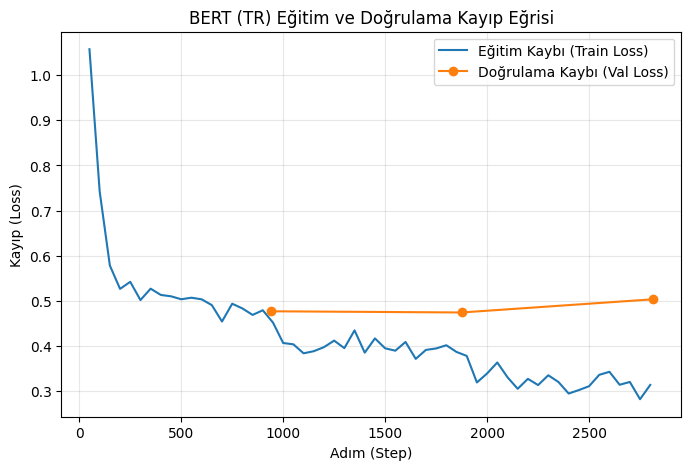

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
# B4: TÜRKÇE BERTURK TAM EĞİTİM VE 3.000 SATIRLIK TAHMİN + LOG + GRAFİK
import pandas as pd
import numpy as np
import torch
import os
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

LANG = "tr"
MODEL_NAME = "dbmdz/bert-base-turkish-cased"
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 3
SEED = 42
OUTPUT_DIR = f"/content/drive/MyDrive/bim448/models/bert_{LANG}{EK}"  # DEBUG: ayrı klasör

LABEL2ID = {"negative": 0, "neutral": 1, "positive": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# 1. Tam Veriyi Oku (30.000 train, 3.000 val, 3.000 test)
train_df = pd.read_csv(f"data/processed/{LANG}_train.csv")
val_df = pd.read_csv(f"data/processed/{LANG}_val.csv")
test_df = pd.read_csv(f"data/processed/{LANG}_test.csv")

if DEBUG:  # hızlı deneme: 300 eğitim / 150 doğrulama / 150 test örneği
    train_df = train_df.sample(300, random_state=SEED).reset_index(drop=True)
    val_df = val_df.sample(150, random_state=SEED).reset_index(drop=True)
    test_df = test_df.sample(150, random_state=SEED).reset_index(drop=True)

print(f"Türkçe Veri boyutları -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

train_df['label_id'] = train_df['label'].map(LABEL2ID)
val_df['label_id'] = val_df['label'].map(LABEL2ID)
test_df['label_id'] = test_df['label'].map(LABEL2ID)

# 2. Tokenize
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

token_lengths = [len(tokenizer.encode(str(t), truncation=False)) for t in test_df['text']]
over_128 = sum(1 for l in token_lengths if l > MAX_LEN) / len(token_lengths) * 100
print(f"📊 Türkçe test metinlerinin %{over_128:.2f}'si {MAX_LEN} tokenı aşıyor.")

def tokenize_function(examples):
    return tokenizer(examples['text'], padding="max_length", truncation=True, max_length=MAX_LEN)

train_ds = Dataset.from_pandas(train_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
val_ds = Dataset.from_pandas(val_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)
test_ds = Dataset.from_pandas(test_df[['text', 'label_id']].rename(columns={'label_id': 'label'})).map(tokenize_function, batched=True)

# 3. Model ve Eğitim Ayarları
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)
print(f"📊 Türkçe Model Toplam Parametre Sayısı: {model.num_parameters():,}")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1}

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=64,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    # Not: warmup_ratio verilmedi (asıl eğitimde de warmup yoktu; rapor 5.9)
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    seed=SEED,
    logging_steps=5 if DEBUG else 50,
    report_to="none"
)

trainer = Trainer(model=model, args=training_args, train_dataset=train_ds, eval_dataset=val_ds, compute_metrics=compute_metrics)

print("🚀 Tam Türkçe BERTurk eğitimi başlıyor...")
train_result = trainer.train()
print(f"⏱️ Toplam Türkçe eğitim süresi: {train_result.metrics['train_runtime']:.2f} saniye")

# 4. Logları ve Kayıp Grafiğini Kaydet
os.makedirs("results/logs", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

log_df = pd.DataFrame(trainer.state.log_history)
log_df.to_csv(f"results/logs/bert_{LANG}_log{EK}.csv", index=False)

train_logs = log_df[log_df['loss'].notna()]
eval_logs = log_df[log_df['eval_loss'].notna()]

plt.figure(figsize=(8, 5))
plt.plot(train_logs['step'], train_logs['loss'], label='Eğitim Kaybı (Train Loss)')
plt.plot(eval_logs['step'], eval_logs['eval_loss'], marker='o', label='Doğrulama Kaybı (Val Loss)')
plt.title(f'BERT ({LANG.upper()}) Eğitim ve Doğrulama Kayıp Eğrisi')
plt.xlabel('Adım (Step)')
plt.ylabel('Kayıp (Loss)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(f"results/figures/bert_{LANG}_loss{EK}.png", dpi=300, bbox_inches='tight')
plt.show()

# 5. En İyi Modeli Drive'a Kaydet ve 3.000 Test Tahmini Üret
trainer.save_model(OUTPUT_DIR + "/best")

predictions = trainer.predict(test_ds)
preds = np.argmax(predictions.predictions, axis=-1)
probs = torch.softmax(torch.tensor(predictions.predictions), dim=-1).numpy()
max_probs = np.max(probs, axis=-1)

result_df = pd.DataFrame({
    'id': test_df['id'],
    'text': test_df['text'],
    'true_label': test_df['label'],
    'pred_label': [ID2LABEL[p] for p in preds],
    'score': max_probs
})

beklenen = 150 if DEBUG else 3000
assert len(result_df) == beklenen, f"HATA: Satır sayısı {beklenen} değil: {len(result_df)}"
result_df.to_csv(f"predictions/bert_{LANG}{EK}.csv", index=False, encoding="utf-8")
print(f"✅ predictions/bert_{LANG}{EK}.csv ({len(result_df)} satır) kaydedildi")

# 6. GitHub'a gönder (yalnızca asıl eğitimde; DEBUG dosyaları gönderilmez)
if not DEBUG:
    !git add predictions/bert_tr.csv results/logs/bert_tr_log.csv results/figures/bert_tr_loss.png
    !git commit -m "[Bilge] BERT Türkçe (3000 satır) tahminleri, log ve kayıp grafiği eklendi"
    !git pull --rebase
    !git push
    print("🚀 Türkçe tüm çıktılar GitHub'a gönderildi!")
else:
    print("ℹ️ DEBUG modu: dosyalar _debug ekiyle kaydedildi, GitHub'a gönderilmedi.")

## 5. Parametre tablosu (B6)

In [ ]:
# B6: BERT parametre tablosunu oluştur (results/tables/bert_parametreler.csv)
import os
import pandas as pd

# Loglardan otomatik okunan değerler: en iyi epoch, en iyi val makro-F1, eğitim süresi
def log_ozeti(dil):
    log = pd.read_csv(f"results/logs/bert_{dil}_log.csv")
    ev = log[log["eval_macro_f1"].notna()]
    en_iyi = ev.loc[ev["eval_macro_f1"].idxmax()]
    sure_sn = log["train_runtime"].dropna().iloc[-1]
    return int(en_iyi["epoch"]), en_iyi["eval_macro_f1"], sure_sn / 60

en_epoch, en_f1, en_dk = log_ozeti("en")
tr_epoch, tr_f1, tr_dk = log_ozeti("tr")

def tr_sayi(x, basamak):          # 0.8024 -> "0,802" (raporda ondalık virgül)
    return f"{x:.{basamak}f}".replace(".", ",")

# Parametre sayısı, 128 token oranı ve GPU: eğitim hücrelerinin çıktısından alındı
tablo = pd.DataFrame([
    ["Model adı", "FacebookAI/roberta-base", "dbmdz/bert-base-turkish-cased"],
    ["Parametre sayısı", "124.647.939", "110.619.651"],
    ["MAX_LEN (token)", "128", "128"],
    ["128 tokenı aşan test metni oranı", "%3,20", "%0,20"],
    ["Öğrenme oranı", "2e-5", "2e-5"],
    ["Batch boyutu (eğitim / değerlendirme)", "32 / 64", "32 / 64"],
    ["Epoch sayısı", "3", "3"],
    ["En iyi epoch (val makro-F1'e göre)", str(en_epoch), str(tr_epoch)],
    ["Optimizer", "AdamW (Trainer varsayılanı)", "AdamW (Trainer varsayılanı)"],
    ["Warmup oranı", "0 (uygulanmadı)", "0 (uygulanmadı)"],
    ["Weight decay", "0,01", "0,01"],
    ["fp16 (karışık duyarlık)", "Evet", "Evet"],
    ["Seed", "42", "42"],
    ["Eğitim örnek sayısı", "30.000", "30.000"],
    ["Eğitim süresi (dk)", tr_sayi(en_dk, 1), tr_sayi(tr_dk, 1)],
    ["GPU", "NVIDIA Tesla T4 (Google Colab)", "NVIDIA Tesla T4 (Google Colab)"],
    ["Val makro-F1 (en iyi epoch)", tr_sayi(en_f1, 3), tr_sayi(tr_f1, 3)],
], columns=["parametre", "ingilizce", "turkce"])

os.makedirs("results/tables", exist_ok=True)
tablo.to_csv("results/tables/bert_parametreler.csv", index=False, encoding="utf-8")
print("✅ results/tables/bert_parametreler.csv oluşturuldu (henüz GitHub'a gönderilmedi)")
display(tablo)

## 6. Hata örnekleri (B8)

In [ ]:
# B8: BERT hata örnekleri (results/hata_ornekleri/bert.csv) — 3 EN + 3 TR, farklı hata türleri
import pandas as pd
import os

# Seçilen örnekler: (dil, id, tek cümlelik açıklama). Metin ve etiketler tahmin dosyasından okunur.
SECIM = [
    ("en", "en_282535", "Cümledeki olumsuzluk (doesn't) aslında övgü bildiriyor; model olumsuz kelimeye takılıp yorumu Negatif saymıştır."),
    ("en", "en_356762", "Karışık duygu: nemlendirme ve renk övülüp tat eleştirilmiş; model iki yönü dengeleyip Nötr tahmin etmiştir."),
    ("en", "en_330232", "Metin açıkça olumsuz olduğu hâlde 3 yıldız verilmiş; yıldızdan türetilen etiketteki gürültüye örnektir."),
    ("tr", "tr_058249", "Karışık duygu: olumsuz eleştiriden sonra 'ancak renk uyumu güzel' denmesi modeli Nötr tahmine yöneltmiştir."),
    ("tr", "tr_053351", "'gelmedi' ve 'fena değil' gibi olumsuzluk ekli ılımlı ifadeler model tarafından Nötr olarak yorumlanmıştır."),
    ("tr", "tr_120335", "Metin ürünü önermiyor ama etiket Pozitif; kullanıcının açıkladığı gibi yüksek puan zorunlulukla verilmiş, etiket gürültüsüdür."),
]
MODEL_AD = {"en": "BERT (RoBERTa)", "tr": "BERT (BERTurk)"}

satirlar = []
for dil, id_, aciklama in SECIM:
    p = pd.read_csv(f"predictions/bert_{dil}.csv", encoding="utf-8", keep_default_na=False)
    r = p[p["id"] == id_].iloc[0]
    assert r["true_label"] != r["pred_label"], f"{id_} yanlış sınıflandırılmış bir örnek değil!"
    satirlar.append({"id": id_, "dil": dil.upper(), "model": MODEL_AD[dil], "text": r["text"],
                     "true_label": r["true_label"], "pred_label": r["pred_label"], "aciklama": aciklama})

hata_df = pd.DataFrame(satirlar)   # sütun sırası: id, dil, model, text, true_label, pred_label, aciklama
os.makedirs("results/hata_ornekleri", exist_ok=True)
hata_df.to_csv("results/hata_ornekleri/bert.csv", index=False, encoding="utf-8")
print(f"✅ results/hata_ornekleri/bert.csv oluşturuldu: {len(hata_df)} örnek ")
display(hata_df)

## 7. GitHub'a gönderim

In [ ]:
# B6 ve B8 çıktılarını GitHub'a gönder (yalnızca asıl çalıştırmada)
if not DEBUG:
    !git add results/tables/bert_parametreler.csv results/hata_ornekleri/bert.csv
    !git commit -m "[Bilge] BERT parametre tablosu ve hata örnekleri güncellendi"
    !git pull --rebase
    !git push
else:
    print("ℹ️ DEBUG modu: GitHub'a gönderim yapılmadı.")